# 00 · Start here: your segmentation laboratory

**Level:** orientation · **Study time:** 25–40 minutes · **Prerequisite:** comfortable with Python.

Image segmentation assigns a label to every pixel. You will move from simple rules to learned
models, then examine where those models fail. This course assumes Python knowledge, but no
segmentation knowledge. You have an NVIDIA GPU; the deep learning lessons use it when PyTorch
can access CUDA. Classical image processing usually stays on the CPU.

**By the end:** select the right kernel, inspect a labeled image, run a baseline, and keep a useful
experiment record. All default examples run locally without dataset downloads. The real-data
and pretrained sections in lesson 10 are explicit opt-ins. Small examples teach the workflow;
they do not establish real-world accuracy or professional expertise.


## 1. Use Jupyter as a laboratory

Select **Image Segmentation (.venv)** as the kernel. A notebook has Markdown cells (explanation)
and code cells (Python). **Shift+Enter** runs a cell and moves forward; **Ctrl+Enter** runs it in place.
Run from top to bottom. Variables survive between cells until you restart the kernel.

For each lesson: **predict → run → inspect → change one parameter → explain**. At the end, use
**Kernel → Restart Kernel and Run All Cells**. This catches accidental dependence on an earlier
experiment. Each notebook starts fresh and creates its own required data; none requires a prior
notebook's saved model. The `learning/` directory contains small readable utilities; keep it beside
`notebooks/`. Open the complete project folder, rather than moving a notebook on its own.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


## 2. Check the environment

`sys.executable` identifies the Python interpreter used by this notebook. If an import fails,
check the kernel first. Installing into a different interpreter does not fix the active kernel.
Package version numbers may differ from the recorded environment; the execution report records
the versions actually tested for this course.


In [2]:
import sys
import importlib.metadata as metadata
from IPython.display import display
import pandas as pd

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
packages = ["numpy", "scipy", "matplotlib", "scikit-image", "scikit-learn", "pandas", "torch", "torchvision"]
rows = []
for package in packages:
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = "Not installed (torch/torchvision needed from lesson 08)"
    rows.append({"package": package, "version": version})
display(pd.DataFrame(rows))


Python: 3.13.15
Interpreter: C:\Users\Hareram ray\AI\ImageSegmentationPractical\.venv\Scripts\python.exe


,package,version
0,numpy,2.5.2
1,scipy,1.18.1
2,matplotlib,3.11.2
3,scikit-image,0.26.0
4,scikit-learn,1.9.1
5,pandas,3.0.6
6,torch,2.11.0+cu128
7,torchvision,0.26.0+cu128


## 3. Confirm GPU computation, not just installation

PyTorch must be built with CUDA support, and the NVIDIA driver must support that build. A local
CUDA toolkit is not required for normal operations using a compatible prebuilt PyTorch wheel.
The cell below performs an actual matrix multiplication on the selected device. A GPU improves
larger training jobs; tiny examples may be faster on the CPU because transfers have overhead.


In [3]:
try:
    import torch
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("PyTorch:", torch.__version__, "| CUDA build:", torch.version.cuda)
    print("Selected device:", DEVICE)
    if DEVICE.type == "cuda":
        properties = torch.cuda.get_device_properties(0)
        print("GPU:", properties.name)
        print("VRAM (GiB):", round(properties.total_memory / 1024**3, 1))
    a = torch.ones((32, 32), device=DEVICE)
    b = a @ a
    assert torch.allclose(b, torch.full_like(b, 32))
    print("Actual computation passed on", b.device)
except ImportError:
    DEVICE = "cpu"
    print("PyTorch is optional for lessons 01–07 and 11; see README before lesson 08.")


PyTorch: 2.11.0+cu128 | CUDA build: 12.8
Selected device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
VRAM (GiB): 8.0


Actual computation passed on cuda:0


## 4. Meet the data and the three segmentation tasks

**Semantic segmentation:** which category occupies each pixel? All disks share class 1.
**Instance segmentation:** which individual object occupies each pixel? Two disks have different
object IDs. **Panoptic segmentation:** every pixel has a semantic category, and countable objects
also have an instance ID; lesson 11 constructs this representation.

Our toy generator returns an RGB image, a semantic mask, and an instance mask. The generator
knows the exact answer, called **ground truth**. Real ground truth comes from annotation and can
contain uncertainty. IDs are categories, not brightness values. The RGB colors used to display a
mask are only a visualization. Foreground means any object of interest; background is class 0.


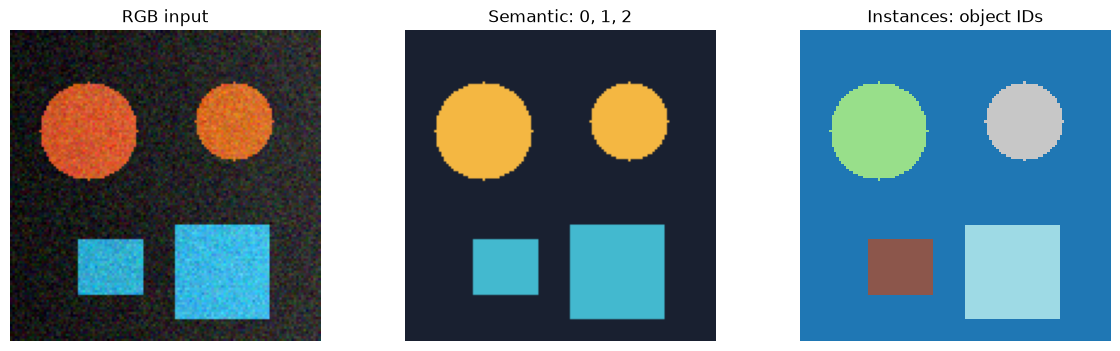

Classes: {0: 'background', 1: 'disk', 2: 'rectangle'}
Image: (128, 128, 3) float32 | Mask: (128, 128) uint8


In [4]:
from learning.data import make_scene, CLASS_NAMES, palette_mask

image, semantic, instances = make_scene(seed=7, size=128)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].imshow(image); axes[0].set_title("RGB input")
axes[1].imshow(palette_mask(semantic)); axes[1].set_title("Semantic: 0, 1, 2")
axes[2].imshow(instances, cmap="tab20", interpolation="nearest"); axes[2].set_title("Instances: object IDs")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Classes:", dict(enumerate(CLASS_NAMES)))
print("Image:", image.shape, image.dtype, "| Mask:", semantic.shape, semantic.dtype)


## 5. Your first segmentation baseline

A **baseline** is a simple solution to compare against. Here a brightness threshold separates
objects from background. The result is binary: object or background. It cannot distinguish disks
from rectangles. Intersection over union (**IoU**) measures overlap: intersection divided by
union. A score of 1 is perfect; 0 means no overlap. Lesson 06 examines the edge cases.

Predict what raising the threshold will do before running this cell. A visually pleasing result
does not guarantee accurate boundaries, so inspect the error image as well.


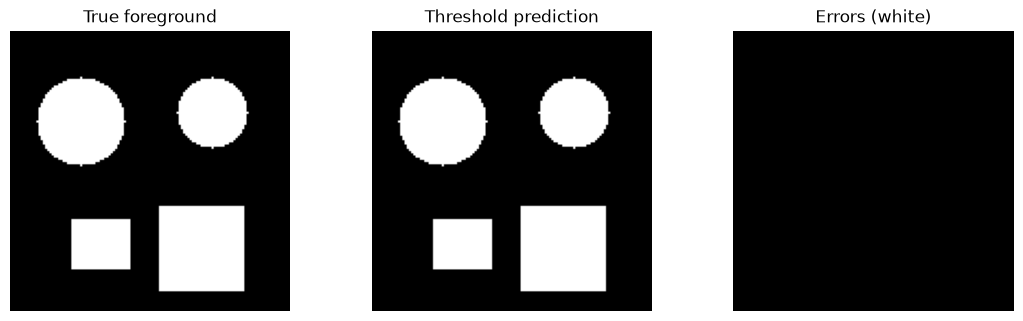

Foreground IoU: 1.000


In [5]:
threshold = 0.32  # Experiment: try 0.20, 0.45, 0.60.
gray = image.mean(axis=-1)
pred = gray > threshold
truth = semantic > 0
intersection = np.logical_and(pred, truth).sum()
union = np.logical_or(pred, truth).sum()
iou = intersection / union if union else 1.0  # Both empty means a correct absence here.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, array, title in zip(axes, [truth, pred, pred != truth],
                          ["True foreground", "Threshold prediction", "Errors (white)"]):
    ax.imshow(array, vmin=0, vmax=1)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"Foreground IoU: {iou:.3f}")


## 6. Learning route

| Lesson | What you build | Main question |
|---|---|---|
| [01](01_images_masks_coordinates.ipynb) | Image and mask toolkit | What exactly is a label? |
| [02](02_thresholding.ipynb) | Global and local thresholds | Can intensity separate the objects? |
| [03](03_morphology_components.ipynb) | Mask cleanup and measurements | Which blobs should remain? |
| [04](04_edges_watershed.ipynb) | Boundary and watershed segmenters | How do we split touching objects? |
| [05](05_clustering_superpixels.ipynb) | Color clusters and superpixels | Can similar pixels form useful regions? |
| [06](06_metrics_error_analysis.ipynb) | Evaluation and error analysis | What does “good” mean? |
| [07](07_classical_machine_learning.ipynb) | Pixel classifier | Can labeled examples replace fixed rules? |
| [08](08_pytorch_segmentation_basics.ipynb) | Trainable pixel network | How does a neural network label pixels? |
| [09](09_unet_training.ipynb) | U-Net training pipeline | How do context and detail work together? |
| [10](10_real_data_transfer_learning.ipynb) | Disk data loader and optional transfer learning | How do I work with real annotations? |
| [11](11_instance_panoptic_prompting.ipynb) | Instance matching and prompted masks | Which object is which? |
| [12](12_advanced_training_deployment.ipynb) | Loss experiments, tiling, and inference | How do I make and audit a complete pipeline? |

Study at your own pace. A useful rhythm is one lesson per session, followed by another session
for its exercises. Reproduce the default first; then increase data and epochs, or try your own
images. Full real-data training takes longer than a demonstration run.


## 7. Keep an experiment record

Change one thing at a time. Record the hypothesis before you run, then compare the observation.
Never tune parameters on the final test set. Training data fits parameters, validation data guides
decisions, and an untouched test set estimates performance after decisions are frozen.


In [6]:
experiment_log = pd.DataFrame([{
    "lesson": "00", "seed": 7, "change": f"threshold={threshold}",
    "hypothesis": "Moderate brightness separates these synthetic objects",
    "metric": "foreground IoU", "value": round(float(iou), 4),
    "observation": "Replace this sentence with what the error image reveals",
    "next_experiment": "Increase threshold while keeping the same image",
}])
display(experiment_log)
# To save your work, uncomment these lines:
# output_dir = PROJECT_ROOT / "artifacts" / "my_experiments"
# output_dir.mkdir(parents=True, exist_ok=True)
# experiment_log.to_csv(output_dir / "lesson_00.csv", index=False)


,lesson,seed,change,hypothesis,metric,value,observation,next_experiment
0,00,7,threshold=0.32,Moderate brightness separates these synthetic ...,foreground IoU,1.0,Replace this sentence with what the error imag...,Increase threshold while keeping the same image


## 8. Practice before continuing

1. Raise the threshold to 0.60. Does false foreground increase, or do true objects disappear?
2. Compare `semantic.max()` with `instances.max()`. Why are the numbers different?
3. Restart the kernel and run every cell. Explain why this is stronger than rerunning only the last cell.

<details><summary>Worked answers — open after trying</summary>

1. Raising the threshold requires brighter pixels. More true foreground is rejected (false negatives).
   Lowering it generally admits more background (false positives). The exact counts depend on noise.
2. `semantic.max()` is 2 because there are two foreground categories; `instances.max()` is 4
   because this generator draws four individually labeled objects. Class IDs and object IDs answer
   different questions; maximum ID is not a safe general object count when IDs have gaps.
3. Restarting removes hidden state. A successful clean run shows that every required variable and
   import is present in the notebook in execution order.

</details>


## Ready to move on?

- [ ] I can identify the active Python interpreter and selected compute device.
- [ ] I can explain the difference between an image, a class mask, and an instance mask.
- [ ] I changed one parameter and recorded a prediction and observation.
- [ ] I ran the notebook from a fresh kernel.

**Troubleshooting:** a busy kernel may be training; wait or interrupt before editing parameters.
For CUDA out-of-memory, reduce batch size or image size and restart the kernel. Keep
`num_workers=0` for these Windows notebooks. If `learning` cannot be imported, restore the whole
project folder. See the root README for installation and kernel instructions.

**Reference:** [JupyterLab notebook guide](https://jupyterlab.readthedocs.io/en/stable/user/notebook.html),
[PyTorch installation selector](https://pytorch.org/get-started/locally/).

**Next:** [01 · Images, masks, and coordinates](01_images_masks_coordinates.ipynb).
